# 🚀 Practice Day 37

**📅 Date:** 2026-10-17  
📁 Category: Phase 3 · 시각화 스토리텔링(Seaborn) (Round 3/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Use Seaborn to visually tell the story of what drives employee salaries — experience, department, and performance
  (Seaborn으로 무엇이 직원 급여를 좌우하는지 — 경력·부서·성과 — 시각적으로 스토리텔링하기)
- Quantify how strongly experience correlates with salary, how pay differs across departments, and whether performance score still matters
  (경력과 급여의 상관관계, 부서별 급여 차이, 성과점수가 급여에 미치는 영향을 정량적으로 파악하기)

---
# 📂 Dataset

**Dataset Name:** Brightpath Inc. — 직원 급여 데이터 / Brightpath Inc. — Employee Compensation Data

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 280 employees (single table) across 6 departments (Engineering, Sales, Marketing, Finance, HR, Operations). Includes years of experience, a performance score (1-5), and salary in USD. Clean — no missing values or duplicates. Several variables jointly shape salary, so the focus is on using Seaborn to visualize those relationships and build a narrative.
(280명의 직원 데이터(단일 테이블)로, 6개 부서(Engineering/Sales/Marketing/Finance/HR/Operations)에 걸쳐 있습니다. 경력연수, 성과점수(1~5), 급여(USD)를 포함하며 결측치·중복 없이 깨끗합니다. 여러 변수가 함께 급여에 영향을 미치는 구조라, Seaborn으로 관계를 시각화하며 스토리를 풀어가는 데 초점을 둡니다.)

## Dataset Preview

In [1]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate employee compensation data across 6 departments ---
n = 280
departments = ['Engineering', 'Sales', 'Marketing', 'Finance', 'HR', 'Operations']
dept_w = [0.24, 0.18, 0.14, 0.14, 0.12, 0.18]
dept_base = {'Engineering': 62000, 'Sales': 48000, 'Marketing': 46000,
             'Finance': 58000, 'HR': 42000, 'Operations': 44000}  # USD

dept_choice = rng.choice(departments, size=n, p=dept_w)
years_experience = np.clip(rng.exponential(6, n), 0, 28).round(1)
performance_score = np.clip(rng.normal(3.4, 0.7, n), 1, 5).round(1)

noise = rng.normal(1.0, 0.10, n)
salary = np.array([dept_base[d] for d in dept_choice]) \
         * (1 + 0.045 * years_experience) \
         * (1 + 0.18 * (performance_score - 3)) \
         * noise
salary = salary.round(-1).astype(int)

df = pd.DataFrame({
    'employee_id': [f'E{str(i+1).zfill(4)}' for i in range(n)],
    'department': dept_choice,
    'years_experience': years_experience,
    'performance_score': performance_score,
    'salary': salary
})

df.head(10)


,employee_id,department,years_experience,performance_score,salary
0,E0001,HR,0.5,3.9,55960
1,E0002,Marketing,0.6,3.9,40220
2,E0003,Operations,3.0,3.7,58460
3,E0004,Finance,0.8,3.8,79470
4,E0005,Engineering,2.0,3.6,66430
5,E0006,Operations,4.5,4.8,67390
6,E0007,HR,0.2,3.3,41300
7,E0008,HR,2.2,3.2,43540
8,E0009,Engineering,9.4,2.9,83810
9,E0010,Marketing,0.4,2.7,50620


## Dataset Information

In [2]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 280 entries, 0 to 279
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   employee_id        280 non-null    str    
 1   department         280 non-null    str    
 2   years_experience   280 non-null    float64
 3   performance_score  280 non-null    float64
 4   salary             280 non-null    int64  
dtypes: float64(2), int64(1), str(2)
memory usage: 11.1 KB

Shape: (280, 5)


,employee_id,department,years_experience,performance_score,salary
count,280,280,280.000000,280.000000,280.000000
unique,280,6,NaN,NaN,NaN
top,E0001,Engineering,NaN,NaN,NaN
freq,1,75,NaN,NaN,NaN
mean,NaN,NaN,6.060357,3.351071,70054.928571
std,NaN,NaN,5.959773,0.696894,22248.363816
min,NaN,NaN,0.100000,1.600000,30040.000000
25%,NaN,NaN,1.675000,2.800000,55015.000000
50%,NaN,NaN,4.000000,3.400000,64200.000000
75%,NaN,NaN,8.300000,3.800000,81685.000000


---
# ❓ Business Questions

1. **(Analysis)** How strong is the correlation between years of experience and salary?
   (경력연수와 급여의 상관관계는 얼마나 강한가?)
2. **(Analysis)** How does average salary differ across the six departments?
   (부서별 평균 급여는 어떻게 다른가?)
3. **(Analysis)** Does performance score still relate to salary — how much do high performers (score ≥4) earn on average compared to low performers (score <3)?
   (성과점수는 급여와 관련이 있는가? 고성과자(4점 이상)와 저성과자(3점 미만)의 평균 급여 차이는?)
4. **(Visualization)** Show the relationship between experience and salary, broken out by department.
   (경력과 급여의 관계를 부서별로 나누어 보면?)
5. **(Visualization)** Show how the salary distribution itself differs across departments.
   (부서별 급여 분포 자체는 어떻게 다른가?)

---
# 🔍 Data Cleaning Check


In [3]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
employee_id          0
department           0
years_experience     0
performance_score    0
salary               0
dtype: int64

Duplicate rows: 0

Dtypes
employee_id              str
department               str
years_experience     float64
performance_score    float64
salary                 int64
dtype: object

Column names
['employee_id', 'department', 'years_experience', 'performance_score', 'salary']

Text columns — unique counts
employee_id    280
department       6
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** How strong is the correlation between years of experience and salary? (경력연수와 급여의 상관관계는 얼마나 강한가?)

**Result:** Pearson correlation is **0.726**. Spearman correlation is **0.614**.  
(피어슨 상관계수는 0.726, 스피어만 상관계수는 0.614)

**Insight:** Both are positive. The Pearson value is **0.112** above the Spearman value, so the straight-line relationship is the stronger of the two.  
(둘 다 양수. 피어슨이 스피어만보다 0.112 높아서, 직선 관계가 둘 중 더 강함)


In [4]:
# Question 1: correlation between years_experience and salary

print(df['years_experience'].corr(df['salary']))
print(df['years_experience'].corr(df['salary'], method='spearman'))

0.7261491601707719


0.6140179386344109


## Question 2

**Question:** How does average salary differ across the six departments? (부서별 평균 급여는 어떻게 다른가?)

**Result:** Engineering **$84,832**, Finance **$81,671**, Marketing **$65,111**, Sales **$60,605**, Operations **$59,500**, HR **$56,356**.  
(Engineering $84,832, Finance $81,671, Marketing $65,111, Sales $60,605, Operations $59,500, HR $56,356)

**Insight:** Engineering is **$28,476** above HR and **$3,161** above Finance, the second highest.  
(Engineering은 HR보다 $28,476, 2위 Finance보다 $3,161 높음)


In [5]:
# Question 2: average salary by department
df.groupby('department')['salary'].mean().sort_values(ascending=False)

department
Engineering    84832.133333
Finance        81670.750000
Marketing      65111.219512
Sales          60605.000000
Operations     59499.777778
HR             56356.285714
Name: salary, dtype: float64

## Question 3

**Question:** Does performance score still relate to salary — how much do high performers earn compared to low performers? (성과점수는 급여와 관련 있는가? 고성과자·저성과자 급여 차이는?)

**Result:** High performers (score ≥ 4) average **$78,013.8**. Low performers (score < 3) average **$59,614.5**. The gap is **$18,399.3**.  
(고성과자(4점 이상) 평균 $78,013.8, 저성과자(3점 미만) 평균 $59,614.5. 차이는 $18,399.3)

**Insight:** High performers earn **$18,399.3** more on average than low performers, so the score still lines up with pay.  
(고성과자 평균이 저성과자보다 $18,399.3 높아서, 점수는 급여와 같이 움직임)


In [6]:
# Question 3: does performance_score relate to salary - compare high vs low performers
high = df.loc[df['performance_score'] >= 4, 'salary'].mean()
low = df.loc[df['performance_score'] < 3, 'salary'].mean()
print("high performers: ", high, "low performers: ", low, "difference: ", high - low)

high performers:  78013.8 low performers:  59614.48717948718 difference:  18399.312820512823


---
# 📈 Visualization

**Chart 1:** Scatter plot with regression line (Seaborn) — experience vs salary, colored by department (Seaborn 산점도+회귀선: 경력 vs 급여, 부서별 색상 구분)

*Interpretation:* One line for all employees slopes up from left to right. That matches the Pearson correlation of **0.726**. Department colors are mixed around the same line.  
(전체 직원에 대한 선 하나가 왼쪽에서 오른쪽으로 올라감. 피어슨 상관계수 0.726과 같음. 부서 색은 그 선 주변에 섞여 있음)

---

**Chart 2:** Box plot or violin plot (Seaborn) — salary distribution by department (Seaborn 박스플롯/바이올린플롯: 부서별 급여 분포)

*Interpretation:* Both plots use the Q2 order: Engineering, Finance, Marketing, Sales, Operations, HR. Engineering and Finance sit higher than HR, whose average is **$56,356** against Engineering's **$84,832**.  
(두 그림 모두 Q2 순서. Engineering, Finance, Marketing, Sales, Operations, HR. Engineering과 Finance가 HR보다 위에 있고, HR 평균 $56,356은 Engineering $84,832보다 낮음)


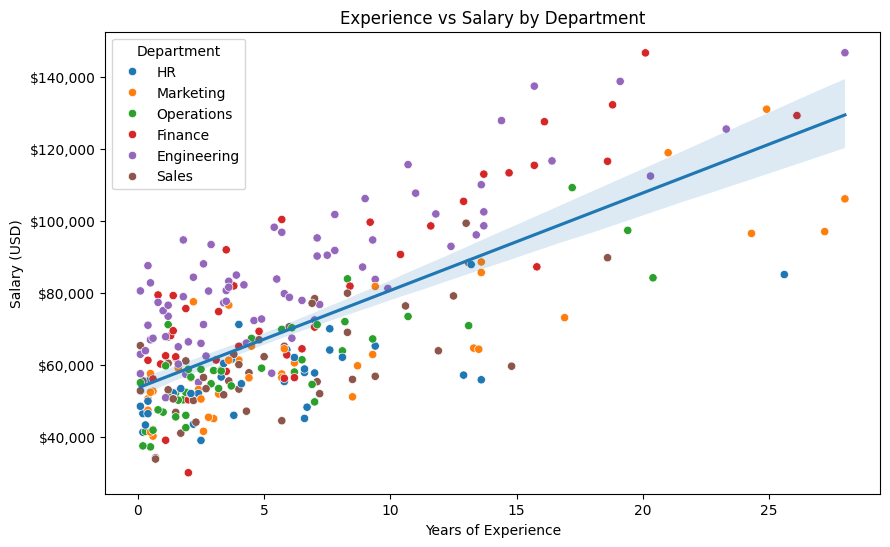

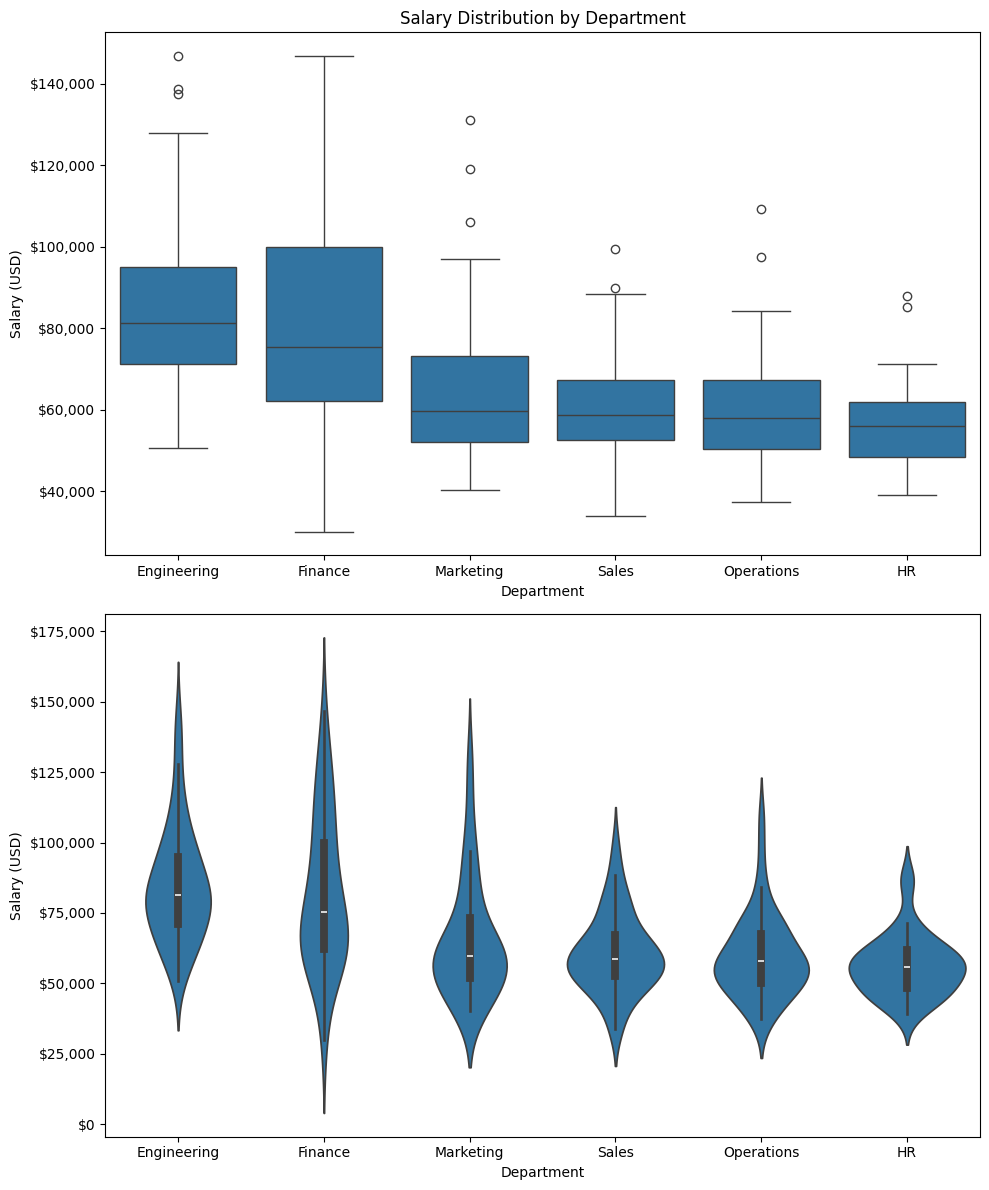

In [7]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: experience vs salary scatter + regression line, colored by department
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(x='years_experience', y='salary', data=df, hue='department', ax=ax)
sns.regplot(x='years_experience', y='salary', data=df, scatter=False, ax=ax)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Experience vs Salary by Department')
ax.set_xlabel('Years of Experience')
ax.set_ylabel('Salary (USD)')
ax.legend(title='Department')
plt.show()

# Chart 2: salary distribution by department
dept_order = df.groupby('department')['salary'].mean().sort_values(ascending=False).index
fig, [ax1, ax2] = plt.subplots(2, 1, figsize=(10, 12))
sns.boxplot(x='department', y='salary', data=df, order=dept_order, ax=ax1)
sns.violinplot(x='department', y='salary', data=df, order=dept_order, ax=ax2)
for ax in (ax1, ax2):
    ax.yaxis.set_major_formatter('${x:,.0f}')
    ax.set_xlabel('Department')
    ax.set_ylabel('Salary (USD)')
ax1.set_title('Salary Distribution by Department')
plt.tight_layout()
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Years of experience and salary move together. The Pearson correlation is **0.726**.  
  (경력연수와 급여는 같이 움직임. 피어슨 상관계수는 0.726)
- Engineering has the highest average salary, **$84,832**. HR has the lowest, **$56,356**.  
  (평균 급여는 Engineering이 $84,832로 가장 높고, HR이 $56,356으로 가장 낮음)
- High performers average **$78,013.8**, which is **$18,399.3** above low performers at **$59,614.5**.  
  (고성과자 평균은 $78,013.8. 저성과자 $59,614.5보다 $18,399.3 높음)  


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Treat experience as the main pay driver. The Pearson correlation with salary is **0.726**.  
   (경력을 급여의 주된 요인으로 보기. 급여와의 피어슨 상관계수는 0.726)
2. Compare HR (**$56,356**) with Engineering (**$84,832**) before setting a department pay band. The gap is **$28,476**.  
   (부서 급여 밴드를 정하기 전에 HR($56,356)과 Engineering($84,832)을 비교하기. 차이는 $28,476)
3. Keep the performance gap visible. Score ≥ 4 averages **$18,399.3** above score < 3.  
   (성과 차이를 급여에서 보이게 두기. 4점 이상은 3점 미만보다 평균 $18,399.3 높음)  


---
# ❌ Mistakes
*What mistakes did I make today?*

- Q3 grouped by every `performance_score` value. The question compares score ≥ 4 with score < 3.  
  (Q3에서 performance_score 값마다 묶음. 질문은 4점 이상과 3점 미만을 비교함)
- Chart 2 called `sns.biolinplot`, which is not a seaborn function. The name is `sns.violinplot`.  
  (차트 2에서 sns.biolinplot을 호출함. seaborn 함수가 아니고 이름은 sns.violinplot)  


---
# ✅ What I Learned
*Today's biggest lesson*

- `.corr()` is Pearson. `.corr(method='spearman')` is the rank correlation. Here Pearson is **0.726** and Spearman is **0.614**.  
  (.corr()는 피어슨. .corr(method='spearman')는 순위 상관. 여기서 피어슨은 0.726, 스피어만은 0.614)
- High vs low performance is two filters, `score >= 4` and `score < 3`, not one group per score.  
  (고성과·저성과는 점수마다 한 그룹이 아니라 score >= 4와 score < 3 두 필터)
- `sns.regplot(..., scatter=False)` adds one line on top of `sns.scatterplot`. `sns.violinplot` is the violin chart.  
  (sns.regplot(..., scatter=False)가 sns.scatterplot 위에 선 하나를 올림. 바이올린 차트는 sns.violinplot)  


---
# 🧠 Reflection

**What was difficult?**  
Choosing the performance groups, and remembering the violin plot function name.  
(성과 구간을 고르는 것과 바이올린 플롯 함수 이름)

**Why?**  
Grouping by each score splits people into tiny bins, and `biolinplot` is not the seaborn name.  
(점수마다 묶으면 사람이 잘게 나뉘고, biolinplot은 seaborn 이름이 아님)

**How did I solve it?**  
Averaged salary for score ≥ 4 and score < 3, and used `sns.violinplot`.  
(4점 이상과 3점 미만의 급여 평균을 내고, sns.violinplot을 씀)

**What would I do differently next time?**  
Read the cutoffs in the question before grouping, and check the seaborn function name.  
(그룹하기 전에 질문에 적힌 기준을 읽고, seaborn 함수 이름을 확인하기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
The correlation, the department averages, and the high-vs-low pay gap are clear. The regression line is one line for every department.  
(상관, 부서 평균, 고성과·저성과 급여 차이는 이해함. 회귀선은 모든 부서에 대한 선 하나)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  
The pandas summaries were short. The performance cutoffs and the violin plot name were the hard part.  
(pandas 요약은 짧았고, 어려운 부분은 성과 기준과 바이올린 플롯 이름이었음)


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 39 — SQL window functions (Round 3/5)  
  (SQL 윈도우 함수 복습)  
